# STEP 6. I-MOD 예비 권역 공간 안정성 검증

**목적:** STEP 5의 상위 40개 지리정보 확인 후보에 대해 DBSCAN과 Complete Linkage를 비교하고, 반경(300/500/800m)에 따라 변하지 않는 구성원 관계와 후보 권역을 정리합니다.

- **입력:** `01_all_286_candidate_flags.csv` (STEP 5 산출물) **1개만 업로드**
- **전체 286개 정류장군을 보존**하고, 공간 분석은 위치가 확인된 적격 후보 40개에서 수행합니다.
- **주의:** 직선거리 기반 탐색적 권역이며 실제 I-MOD 운행권역, 미충족수요, 서비스 효율의 실증 결과가 아닙니다. Complete Linkage의 군집 내 최대거리 제한은 직선거리 기준입니다.
- 반경 800m까지 동일하게 묶이는 그룹을 '**견고한 핵심 그룹**'으로 표시하되, 반경 300m에서도 함께 묶이는지 별도로 기록합니다. 이는 인과적 안정성이 아니라 매개변수 민감도 분석입니다.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from sklearn.cluster import DBSCAN
from sklearn.metrics import adjusted_rand_score
from pathlib import Path
from IPython.display import display
from google.colab import files
OUT=Path('IMOD_STEP6_Results');OUT.mkdir(exist_ok=True)
print('STEP 5 산출물 01_all_286_candidate_flags.csv 파일 1개를 업로드하세요.')
up=files.upload()
paths=[name for name in up if 'all_286_candidate_flags' in name and name.lower().endswith('.csv')]
if len(paths)!=1: raise ValueError('01_all_286_candidate_flags.csv 1개가 필요합니다. 업로드 목록: '+str(list(up)))
df=pd.read_csv(paths[0],encoding='utf-8-sig')
required=['station_name','eligible_median','spatial_valid','rank_base','score_base','top20_frequency','avg_daily_passengers','avg_daily_operations','temporal_mismatch','representative_latitude','representative_longitude']
missing=[c for c in required if c not in df.columns]
if missing:raise ValueError('누락 컬럼: '+str(missing))
assert len(df)==286 and df.station_name.nunique()==286, '입력 파일의 286개 고유 정류장명을 확인하세요'
print('전체 행:',len(df),'좌표 확정:',df.spatial_valid.sum())

STEP 5 산출물 01_all_286_candidate_flags.csv 파일 1개를 업로드하세요.


Saving 01_all_286_candidate_flags.csv to 01_all_286_candidate_flags.csv
전체 행: 286 좌표 확정: 249


## 1. STEP 5 기준으로 동일한 후보 40개 재구성

In [2]:
pool=(df.loc[df.eligible_median.astype(bool)&df.spatial_valid.astype(bool)]
    .sort_values(['rank_base','station_name'],kind='stable').head(40).copy().reset_index(drop=True))
assert len(pool)==40
assert pool[['representative_latitude','representative_longitude']].notna().all().all()
print('공간 후보',len(pool),'미확정 좌표 보류',int((~df.spatial_valid.astype(bool)).sum()))
display(pool[['station_name','rank_base','score_base','top20_frequency']].head(12))

공간 후보 40 미확정 좌표 보류 37


,station_name,rank_base,score_base,top20_frequency
0,남중학교,3,73.776224,3
1,롯데백화점(인천터미널),5,72.132867,3
2,문학경기장(야구장),7,69.318182,2
3,주안역,10,68.846154,3
4,문학초등학교,12,67.290210,3
5,용현3동행정복지센터.보훈병원,13,67.220280,3
6,한양아파트,15,66.486014,2
7,주안7동행정복지센터,18,65.559441,3
8,신기.남부종합시장(진흥사거리),19,65.122378,2
9,시티오씨엘4단지,21,64.562937,0


## 2. 두 공간 군집 알고리즘을 같은 입력으로 비교
DBSCAN의 `min_samples=1`은 연결요소 방식(연쇄 연결 가능); Complete Linkage는 군집 내 모든 쌍의 거리가 설정 반경 이하가 되도록 구성합니다.

,method,radius_m,n_groups,n_multistop,n_singletons,largest_group,max_group_diameter_m
0,DBSCAN,300,34,5,29,3,473.7
1,DBSCAN,500,22,8,14,7,1254.2
2,DBSCAN,800,6,4,2,28,4583.4
3,Complete,300,35,5,30,2,286.2
4,Complete,500,26,12,14,3,492.3
5,Complete,800,18,13,5,5,693.2


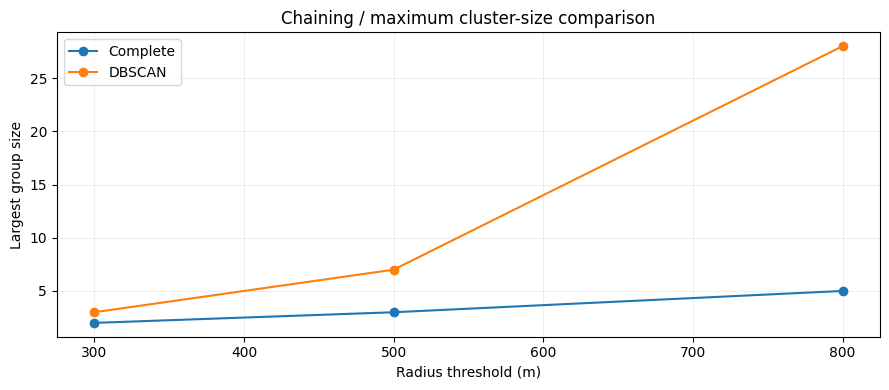

In [3]:
R=6371000.0
lat=np.radians(pool.representative_latitude.to_numpy(float))
lon=np.radians(pool.representative_longitude.to_numpy(float))
dlat=lat[:,None]-lat[None,:];dlon=lon[:,None]-lon[None,:]
a=np.sin(dlat/2)**2 + np.cos(lat[:,None])*np.cos(lat[None,:])*np.sin(dlon/2)**2
D=2*R*np.arcsin(np.sqrt(np.clip(a,0,1)))
np.fill_diagonal(D,0)
assert np.allclose(D,D.T) and np.allclose(np.diag(D),0)
Z=linkage(squareform(D,checks=True),method='complete')

def group_labels(method,radius):
    if method=='DBSCAN':return DBSCAN(eps=radius,min_samples=1,metric='precomputed').fit_predict(D)
    return fcluster(Z,t=radius,criterion='distance')-1

def summary_of_labels(lbl):
    labels=np.asarray(lbl)
    sizes=pd.Series(labels).value_counts()
    diameters=[D[np.ix_(np.where(labels==v)[0],np.where(labels==v)[0])].max() for v in sizes.index]
    return {'n_groups':len(sizes),'n_multistop':int((sizes>=2).sum()),'n_singletons':int((sizes==1).sum()),
            'largest_group':int(sizes.max()),'max_group_diameter_m':round(float(max(diameters)),1)}

labels={};rows=[]
for method in ['DBSCAN','Complete']:
    for radius in [300,500,800]:
        lab=group_labels(method,radius);labels[(method,radius)]=lab
        rows.append({'method':method,'radius_m':radius,**summary_of_labels(lab)})
results=pd.DataFrame(rows)
results.to_csv(OUT/'01_algorithm_radius_comparison.csv',index=False,encoding='utf-8-sig')
display(results)
fig,ax=plt.subplots(figsize=(9,4))
for method,g in results.groupby('method'):
    ax.plot(g.radius_m,g.largest_group,marker='o',label=method)
ax.set(xlabel='Radius threshold (m)',ylabel='Largest group size',title='Chaining / maximum cluster-size comparison')
ax.legend();ax.grid(alpha=.2);plt.tight_layout();plt.savefig(OUT/'02_largest_group_vs_radius.png',dpi=170);plt.show()

## 3. 같은 그룹에 배정된 정류장 쌍의 안정성
반경과 알고리즘 변경 시 공동 배정(co-assignment) 관계를 Jaccard로 비교합니다. 단독 후보는 안정 쌍 분석에는 나타나지 않습니다.

In [4]:
from itertools import combinations

def pairs_from_labels(lab):
    return {(i,j) for i,j in combinations(range(len(lab)),2) if lab[i]==lab[j]}
sets={key:pairs_from_labels(lab) for key,lab in labels.items()}
comparisons=[]
for a,b in combinations(labels,2):
    A,B=sets[a],sets[b]
    comparisons.append({'config_a':f'{a[0]}_{a[1]}m','config_b':f'{b[0]}_{b[1]}m',
                        'jaccard':len(A&B)/len(A|B) if A|B else np.nan,
                        'coassigned_pairs_a':len(A),'coassigned_pairs_b':len(B),
                        'ARI':adjusted_rand_score(labels[a],labels[b])})
comp=pd.DataFrame(comparisons)
comp.to_csv(OUT/'03_pair_stability_comparison.csv',index=False,encoding='utf-8-sig')
display(comp.sort_values('jaccard').head(10))

# 반경 300,500,800m의 Complete Linkage에서 모두 공동 배정된 쌍
stable_pairs=set.intersection(*(sets[('Complete',r)] for r in [300,500,800]))
edge_rows=[]
for i,j in sorted(stable_pairs):
    edge_rows.append({'station_a':pool.station_name[i],'station_b':pool.station_name[j],
                      'distance_m':round(float(D[i,j]),2),
                      'both_in_DBSCAN_500m':(i,j) in sets[('DBSCAN',500)]})
edges=pd.DataFrame(edge_rows,columns=['station_a','station_b','distance_m','both_in_DBSCAN_500m'])
edges.to_csv(OUT/'04_stable_core_pairs.csv',index=False,encoding='utf-8-sig')
print('Complete Linkage 300/500/800m 공통 정류장 쌍:',len(edges))

,config_a,config_b,jaccard,coassigned_pairs_a,coassigned_pairs_b,ARI
9,DBSCAN_800m,Complete_300m,0.012658,395,5,0.012498
1,DBSCAN_300m,DBSCAN_800m,0.017722,7,395,0.017498
10,DBSCAN_800m,Complete_500m,0.040506,395,16,0.040008
11,DBSCAN_800m,Complete_800m,0.091139,395,36,0.090076
5,DBSCAN_500m,DBSCAN_800m,0.106329,42,395,0.105109
6,DBSCAN_500m,Complete_300m,0.119048,42,5,0.203642
4,DBSCAN_300m,Complete_800m,0.131579,7,36,0.220850
13,Complete_300m,Complete_800m,0.138889,5,36,0.235294
0,DBSCAN_300m,DBSCAN_500m,0.166667,7,42,0.274554
3,DBSCAN_300m,Complete_500m,0.277778,7,16,0.427636


Complete Linkage 300/500/800m 공통 정류장 쌍: 5


## 4. 기본 권역(Complete Linkage, 500m) 분석
최종 운영권역으로 확정하지 않고, 지름 제약을 만족하는 탐색적 후보 묶음으로 사용합니다.

In [5]:
base=pool.copy();base['cluster_number']=labels[('Complete',500)]
# 군집번호는 중심점 좌표 순으로 다시 매김(모델 내부 레이블 번호에 의미를 두지 않음)
ordered=sorted(base.cluster_number.unique(), key=lambda k:(base.loc[base.cluster_number==k,'representative_latitude'].mean(),base.loc[base.cluster_number==k,'representative_longitude'].mean()))
mapid={k:f'Z{i+1:02d}' for i,k in enumerate(ordered)}
base['zone_id']=base.cluster_number.map(mapid)
base['is_multistop']=base.zone_id.map(base.zone_id.value_counts())>=2
base.to_csv(OUT/'05_complete500_assignments.csv',index=False,encoding='utf-8-sig')
zone=[]
for zid,g in base.groupby('zone_id'):
    ix=g.index.to_numpy(); dia=float(D[np.ix_(ix,ix)].max())
    zone.append({'zone_id':zid,'n_stop_groups':len(g),'names':' | '.join(g.station_name),
                 'diameter_m':round(dia,1),'sum_avg_daily_passengers':round(g.avg_daily_passengers.sum(),1),
                 'sum_avg_daily_operations':round(g.avg_daily_operations.sum(),1),
                 'median_temporal_mismatch':round(g.temporal_mismatch.median(),4),
                 'mean_screening_score':round(g.score_base.mean(),2),
                 'n_repeat_2plus':int((g.top20_frequency>=2).sum()),
                 'lat':g.representative_latitude.mean(),'lon':g.representative_longitude.mean()})
profiles=pd.DataFrame(zone).sort_values(['n_stop_groups','n_repeat_2plus','mean_screening_score'],ascending=False)
profiles.to_csv(OUT/'06_complete500_zone_profiles.csv',index=False,encoding='utf-8-sig')
display(profiles.head(20))
assert (profiles.diameter_m<=500.1).all()
print('다중 권역:',sum(profiles.n_stop_groups>1),'단독:',sum(profiles.n_stop_groups==1))

,zone_id,n_stop_groups,names,diameter_m,sum_avg_daily_passengers,sum_avg_daily_operations,median_temporal_mismatch,mean_screening_score,n_repeat_2plus,lat,lon
13,Z14,3,인하대역4번출구 | 용현고가교 | 굴다리,492.3,1260.5,1245.8,0.2143,62.79,0,37.451390,126.648132
14,Z15,3,주안남초등학교 | 힐스테이트푸르지오주안 | 국민건강보험남부지사,491.6,2387.8,1860.9,0.1691,58.53,0,37.451894,126.680363
9,Z10,2,주안7동행정복지센터 | 신기.남부종합시장(진흥사거리),175.8,3791.1,1909.5,0.1842,65.34,2,37.447901,126.678433
22,Z23,2,남중학교 | 인화여고,484.6,1042.7,1628.3,0.2378,66.61,1,37.466884,126.654319
21,Z22,2,주안역 | 주안역환승정류장,122.3,11853.1,2257.4,0.1916,64.27,1,37.464005,126.680507
12,Z13,2,한양아파트 | 토지금고시장,175.1,869.5,528.9,0.2037,63.32,1,37.451179,126.638156
6,Z07,2,시티오씨엘4단지 | 힐스테이트학익104동앞,391.2,869.1,1284.7,0.2322,62.15,0,37.443221,126.648410
16,Z17,2,인천기계공고 | 용남시장,324.2,1845.1,1477.1,0.1941,61.76,0,37.453538,126.667726
20,Z21,2,숭의보건지소 | 숭의교회,439.4,1462.8,833.2,0.1687,61.15,0,37.462685,126.646856
8,Z09,2,인하대정문 | 인하대역(7번출구),310.1,4661.6,2495.3,0.2219,60.66,0,37.447386,126.652098


다중 권역: 12 단독: 14


## 5. 우선 검토 후보를 위한 비보상적 기준
순위표는 실험적 검토용입니다. **점수가 높아도** 지름이 크거나 소수 구성원이 불안정하면 자동으로 최종 채택하지 않습니다. 다양성을 위해 단독 고득점 후보도 별도 표기합니다.

In [6]:
# 300m Complete linkage에서는 같은 그룹인데 500m에서도 유지되는 정류장 쌍은 기초 공간 핵심
core_stations=set()
for i,j in stable_pairs:core_stations.add(pool.station_name[i]);core_stations.add(pool.station_name[j])
base['stable_core_member']=base.station_name.isin(core_stations)
zonecore=base.groupby('zone_id')['stable_core_member'].sum().rename('stable_core_n')
profiles=profiles.merge(zonecore,left_on='zone_id',right_index=True,how='left')
profiles['candidate_status']=np.select(
    [(profiles.n_stop_groups>=2)&(profiles.stable_core_n>=2)&(profiles.n_repeat_2plus>=1),
     (profiles.n_stop_groups>=2),
     (profiles.n_stop_groups==1)&(profiles.mean_screening_score>=pool.score_base.quantile(.75))],
    ['stable_repeat_review','additional_spatial_review','high_score_singleton_review'],default='singleton_monitor')
profiles=profiles.sort_values(['candidate_status','n_repeat_2plus','mean_screening_score'],ascending=[True,False,False]).reset_index(drop=True)
profiles.to_csv(OUT/'07_review_priority_zone_list.csv',index=False,encoding='utf-8-sig')
# 상위 4~6개 강제 선정을 하지 않음. 기준 충족 권역을 우선 검토한다.
display(profiles[['zone_id','names','n_stop_groups','diameter_m','n_repeat_2plus','stable_core_n','mean_screening_score','candidate_status']].head(25))
print('검토 구분:',profiles.candidate_status.value_counts().to_dict())

,zone_id,names,n_stop_groups,diameter_m,n_repeat_2plus,stable_core_n,mean_screening_score,candidate_status
0,Z23,남중학교 | 인화여고,2,484.6,1,0,66.61,additional_spatial_review
1,Z14,인하대역4번출구 | 용현고가교 | 굴다리,3,492.3,0,2,62.79,additional_spatial_review
2,Z07,시티오씨엘4단지 | 힐스테이트학익104동앞,2,391.2,0,0,62.15,additional_spatial_review
3,Z17,인천기계공고 | 용남시장,2,324.2,0,0,61.76,additional_spatial_review
4,Z21,숭의보건지소 | 숭의교회,2,439.4,0,0,61.15,additional_spatial_review
5,Z09,인하대정문 | 인하대역(7번출구),2,310.1,0,0,60.66,additional_spatial_review
6,Z20,인천가정법원.인천지방법원등기국 | KT인천지사,2,478.1,0,0,59.81,additional_spatial_review
7,Z24,공단시장 | 태화아파트,2,349.9,0,0,58.77,additional_spatial_review
8,Z15,주안남초등학교 | 힐스테이트푸르지오주안 | 국민건강보험남부지사,3,491.6,0,2,58.53,additional_spatial_review
9,Z06,롯데백화점(인천터미널),1,0.0,1,0,72.13,high_score_singleton_review


검토 구분: {'singleton_monitor': 10, 'additional_spatial_review': 9, 'high_score_singleton_review': 4, 'stable_repeat_review': 3}


## 6. 반경별 구성원 변화와 표시용 지도

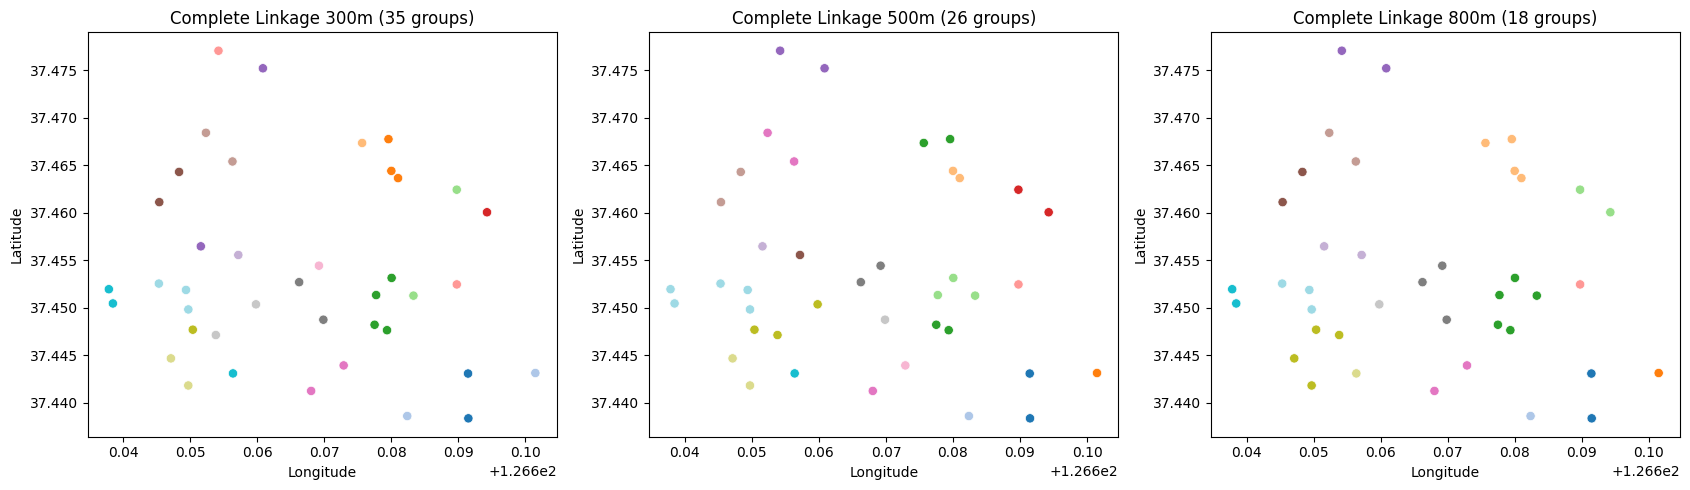

In [7]:
from sklearn.decomposition import PCA
fig,axes=plt.subplots(1,3,figsize=(17,5))
for ax,r in zip(axes,[300,500,800]):
    lab=labels[('Complete',r)]
    ax.scatter(pool.representative_longitude,pool.representative_latitude,c=lab,cmap='tab20',s=45,edgecolors='white',linewidths=.5)
    ax.set(xlabel='Longitude',ylabel='Latitude',title=f'Complete Linkage {r}m ({len(set(lab))} groups)')
plt.tight_layout();plt.savefig(OUT/'08_complete_radius_maps.png',dpi=180);plt.show()
try:
    import folium
    center=[base.representative_latitude.mean(),base.representative_longitude.mean()]
    fmap=folium.Map(location=center,zoom_start=12,tiles='OpenStreetMap')
    for _,r in base.iterrows():
        popup=f'{r.station_name} | {r.zone_id} | Score: {r.score_base:.1f}'
        folium.CircleMarker([r.representative_latitude,r.representative_longitude],radius=5,fill=True,fill_opacity=.85,popup=popup).add_to(fmap)
    fmap.save(str(OUT/'09_exploratory_map.html'))
    display(fmap)
except ImportError:
    print('folium 미설치: HTML 지도 생략. 정적 산점도 결과는 정상 저장되었습니다.')

## 7. 수집·품질 제한과 결과 ZIP 저장

In [8]:
audit=pd.DataFrame([
 {'item':'total_stop_groups','value':len(df)},
 {'item':'geocoded_stop_groups','value':int(df.spatial_valid.sum())},
 {'item':'spatially_unresolved','value':int((~df.spatial_valid.astype(bool)).sum())},
 {'item':'eligible_geocoded_top_pool','value':len(pool)},
 {'item':'complete_500_multi_zones','value':int((profiles.n_stop_groups>1).sum())},
 {'item':'complete_500_singletons','value':int((profiles.n_stop_groups==1).sum())},
 {'item':'complete_500_max_diameter','value':float(profiles.diameter_m.max())},
 {'item':'spatial_method_note','value':'Haversine straight-line distance; not walk network travel distance'},
 {'item':'inference_note','value':'Spatial screening only; no measured unmet demand or I-MOD effect'}
])
audit.to_csv(OUT/'10_analysis_audit.csv',index=False,encoding='utf-8-sig')
from zipfile import ZipFile,ZIP_DEFLATED
zipname='Michuhol_IMOD_STEP6_Spatial_Stability_Results.zip'
with ZipFile(zipname,'w',ZIP_DEFLATED) as z:
    for p in sorted(OUT.iterdir()):z.write(p,arcname=p.name)
print('완료:',zipname,'파일',len(list(OUT.iterdir())),'개')
files.download(zipname)

완료: Michuhol_IMOD_STEP6_Spatial_Stability_Results.zip 파일 10 개


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>